In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/data_group5.csv')
df.drop(columns = ['sr_no'],  inplace = True)

As sr_no column is not an input feature, it is dropped.


In [ ]:
df.isnull().sum()

,0
x,0
y,0
z,0
f,0


As there is no null value in the dataset, we do not have to run any command to handle null values.


In [ ]:
#we have to shuffle and split the dataframe in a ratio of 75:15:10

In [ ]:
print(df.head())

           x          y          z         f
0 -81.676226 -62.424837  48.488491 -0.389217
1  48.848608 -22.458462 -17.243589  2.618250
2  -4.091858  35.213060 -70.472387 -0.868348
3  86.376067 -72.306590 -42.694652  3.207185
4 -71.361489 -36.541999 -54.975949  0.389713


In [ ]:
X = df[['x', 'y', 'z']]
F = df['f']

print(df.head())
print(df.describe())
print(df.info())


           x          y          z         f
0 -81.676226 -62.424837  48.488491 -0.389217
1  48.848608 -22.458462 -17.243589  2.618250
2  -4.091858  35.213060 -70.472387 -0.868348
3  86.376067 -72.306590 -42.694652  3.207185
4 -71.361489 -36.541999 -54.975949  0.389713
                  x             y             z             f
count  30000.000000  30000.000000  30000.000000  30000.000000
mean      -0.301501     -0.151580      1.182146      0.637895
std       57.676286     57.896548     57.760185      5.076327
min     -100.088861   -100.097894   -100.096636    -47.399150
25%      -50.053297    -50.390559    -48.758271     -0.485681
50%       -0.558977     -0.202918      1.562377      0.625750
75%       49.350097     49.557964     51.378707      1.744018
max      100.098932    100.094497    100.096408     49.498276
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------

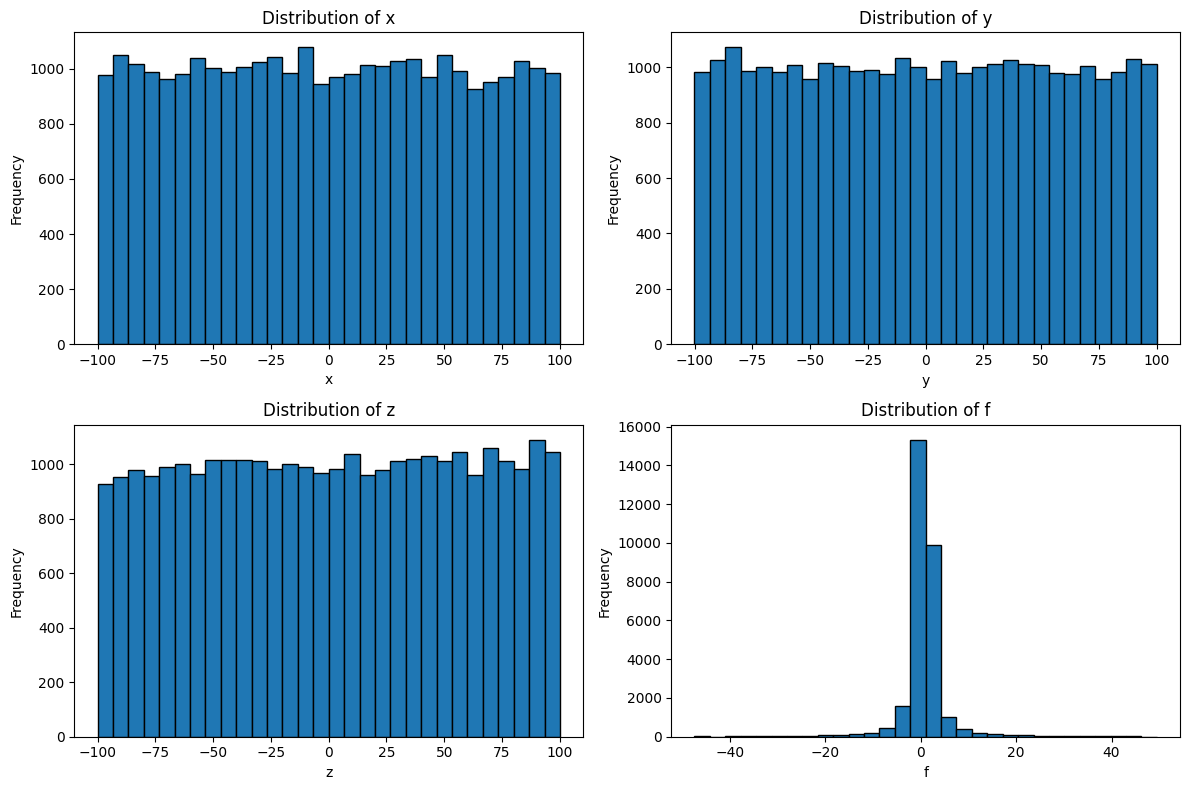

In [ ]:

columns = ['x', 'y', 'z', 'f']

plt.figure(figsize=(12, 8))

for i, column in enumerate(columns):
    plt.subplot(2, 2, i + 1)

    plt.hist(df[column], bins=30, edgecolor='black')

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

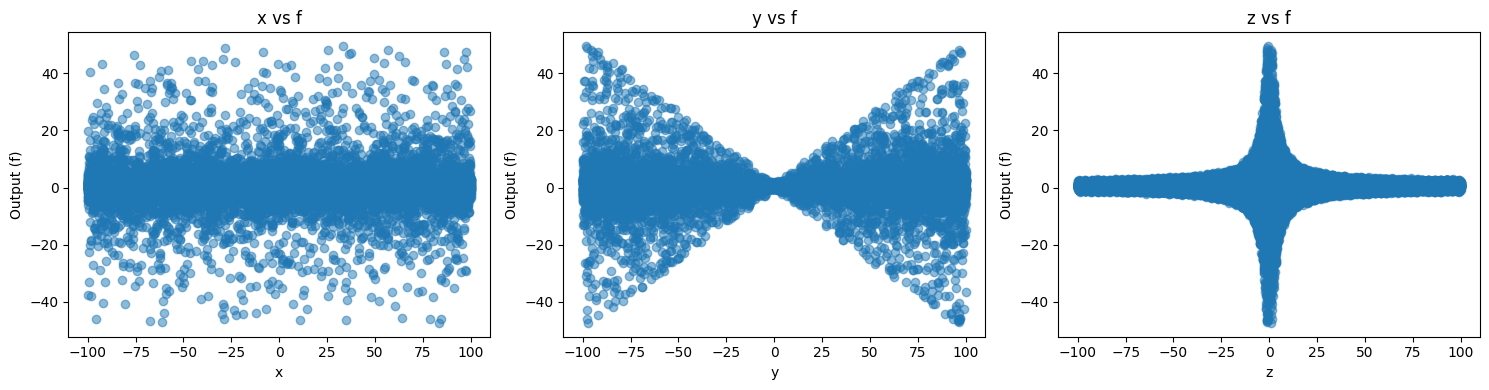

In [ ]:
inputs = ['x', 'y', 'z']

plt.figure(figsize=(15, 4))

for i, column in enumerate(inputs):
    plt.subplot(1, 3, i + 1)

    plt.scatter(df[column], df['f'], alpha=0.5)

    plt.xlabel(column)
    plt.ylabel('Output (f)')
    plt.title(f'{column} vs f')

plt.tight_layout()
plt.show()

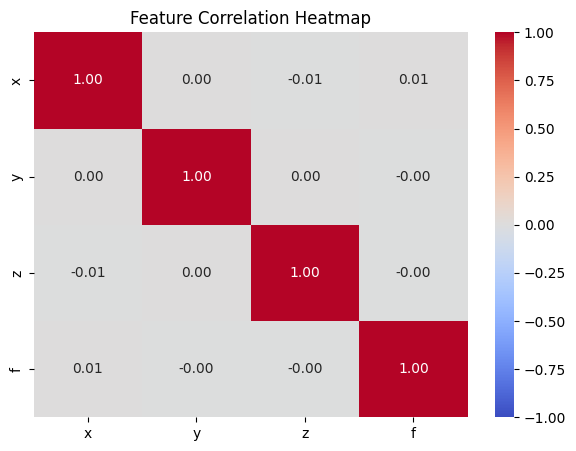

In [ ]:
correlation = df[['x', 'y', 'z', 'f']].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Feature Correlation Heatmap')
plt.show()

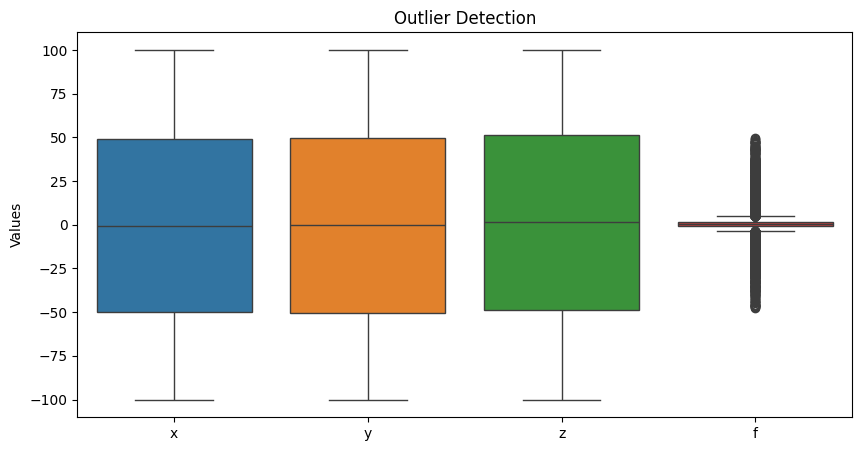

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[['x', 'y', 'z', 'f']])

plt.title('Outlier Detection')
plt.ylabel('Values')

plt.show()

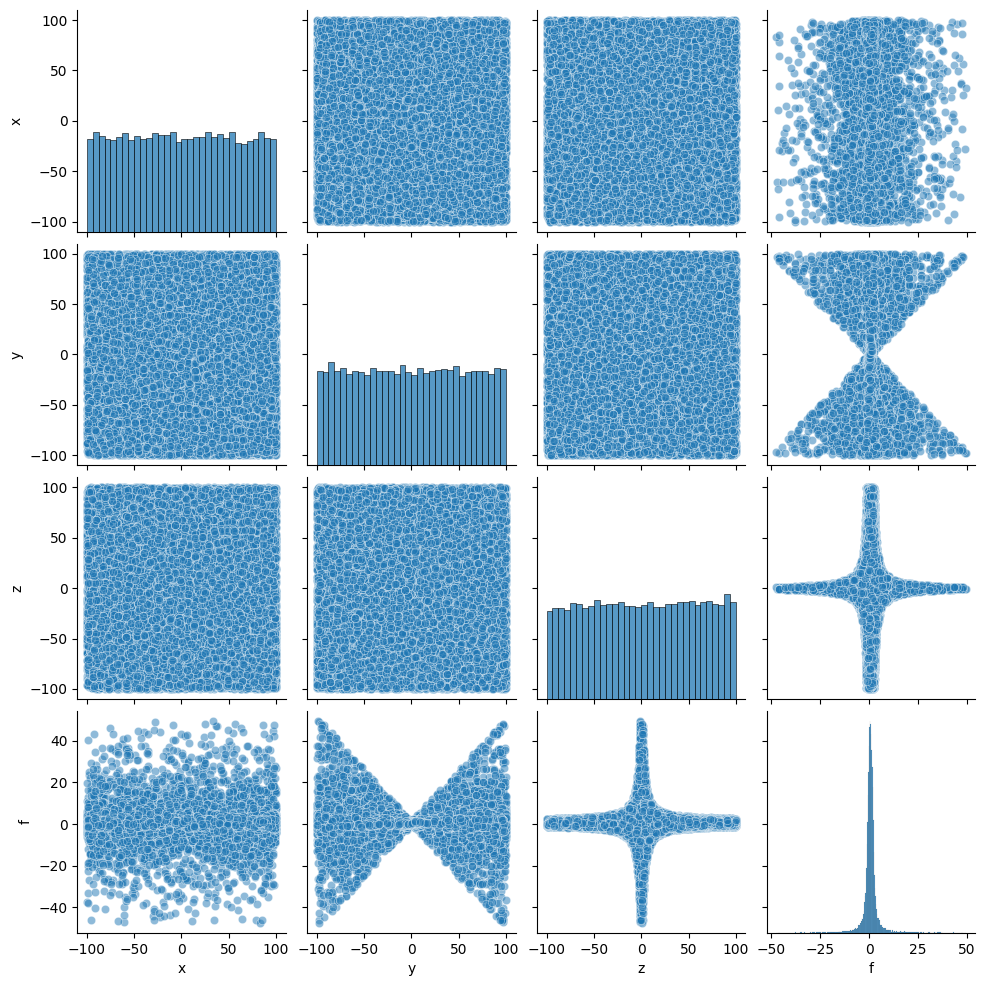

In [ ]:
sns.pairplot(
    df[['x', 'y', 'z', 'f']],
    diag_kind='hist',
    plot_kws={'alpha': 0.5}
)

plt.show()

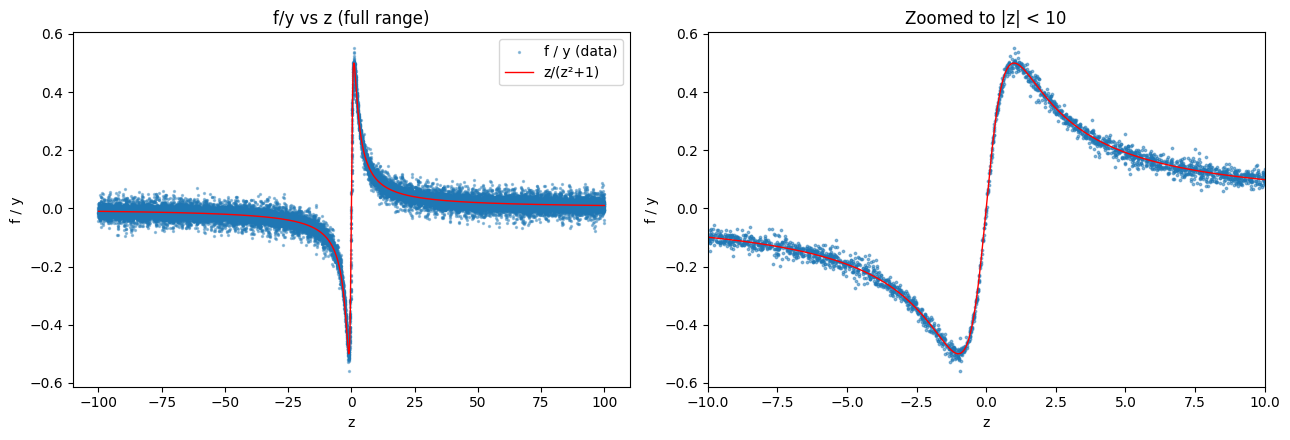

residual std: 0.5319462176265739 | f std: 5.076326784040188
max |residual|: 1.9754145986651146


In [8]:
m = np.abs(df["y"]) > 20            # skip tiny y, where f/y blows up
z_m = df.loc[m, "z"]
ratio = df.loc[m, "f"] / df.loc[m, "y"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# full range
ax[0].scatter(z_m, ratio, s=2, alpha=0.4, label="f / y (data)")
zz = np.linspace(-100, 100, 4000)
ax[0].plot(zz, zz / (zz**2 + 1), "r", lw=1, label="z/(z²+1)")
ax[0].set_xlabel("z"); ax[0].set_ylabel("f / y")
ax[0].set_title("f/y vs z (full range)"); ax[0].legend()

# zoomed near z = 0
ax[1].scatter(z_m, ratio, s=3, alpha=0.5)
zz = np.linspace(-10, 10, 2000)
ax[1].plot(zz, zz / (zz**2 + 1), "r", lw=1)
ax[1].set_xlim(-10, 10)
ax[1].set_xlabel("z"); ax[1].set_ylabel("f / y")
ax[1].set_title("Zoomed to |z| < 10")

plt.tight_layout(); plt.show()

# how close is f to y*z/(z²+1)?
resid = df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)
print("residual std:", resid.std(), "| f std:", df["f"].std())
print("max |residual|:", resid.abs().max())

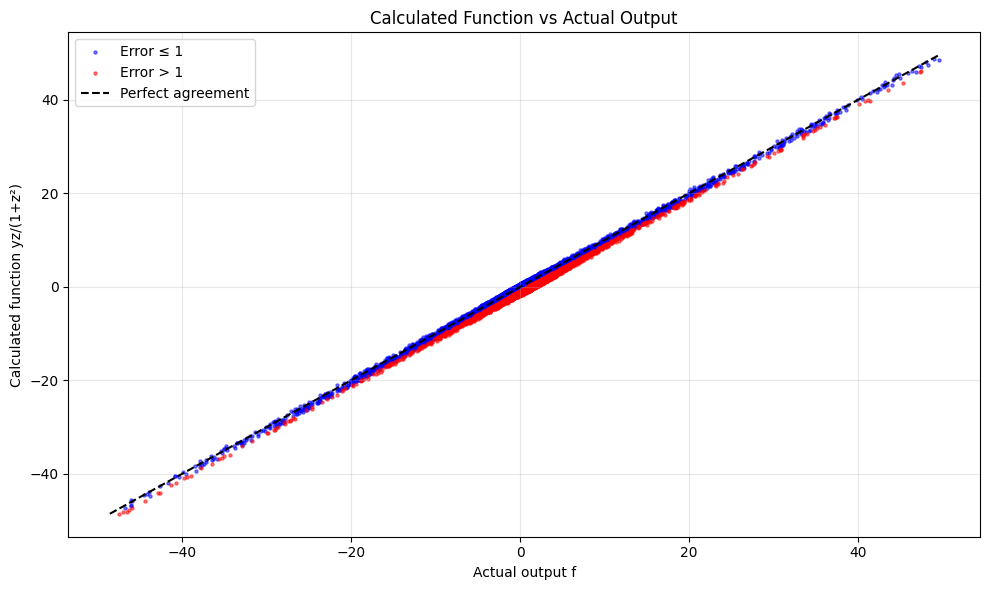

Points with error ≤ 1: 22450
Points with error > 1: 7550
Mean absolute error: 0.68698290936573


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data_group5.csv")

# Calculate theoretical function
f_calc = (df["y"] * df["z"]) / (1 + df["z"]**2)

# Calculate absolute error
error = np.abs(f_calc - df["f"])

# Separate points
low_error = error <= 1
high_error = error > 1

plt.figure(figsize=(10, 6))

plt.scatter(df.loc[low_error, "f"], f_calc[low_error],
            s=5, alpha=0.5, color="blue", label="Error ≤ 1")

plt.scatter(df.loc[high_error, "f"], f_calc[high_error],
            s=5, alpha=0.5, color="red", label="Error > 1")

# Perfect agreement line
lims = [
    min(df["f"].min(), f_calc.min()),
    max(df["f"].max(), f_calc.max())
]

plt.plot(lims, lims, "k--", label="Perfect agreement")

plt.xlabel("Actual output f")
plt.ylabel("Calculated function yz/(1+z²)")
plt.title("Calculated Function vs Actual Output")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Error statistics
print("Points with error ≤ 1:", low_error.sum())
print("Points with error > 1:", high_error.sum())
print("Mean absolute error:", error.mean())

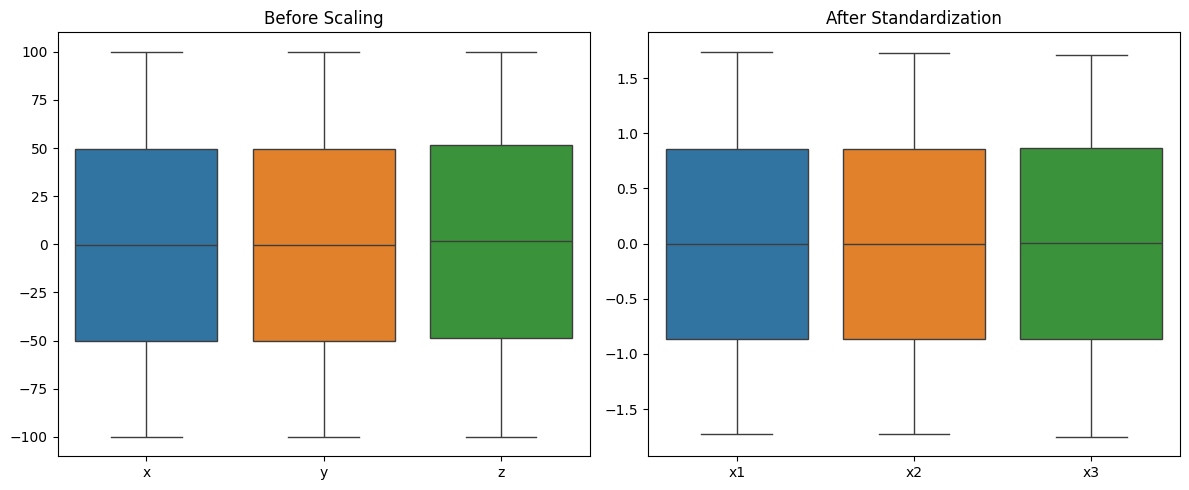

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=['x1', 'x2', 'x3']
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=X)
plt.title('Before Scaling')

plt.subplot(1, 2, 2)
sns.boxplot(data=scaled_df)
plt.title('After Standardization')

plt.tight_layout()
plt.show()

In [ ]:
print(df[['x', 'y', 'z', 'f']].corr())

          x         y         z         f
x  1.000000  0.001406 -0.006845  0.006226
y  0.001406  1.000000  0.001712 -0.000206
z -0.006845  0.001712  1.000000 -0.000279
f  0.006226 -0.000206 -0.000279  1.000000


In [4]:

import pandas as pd
df = pd.read_csv('data_group5.csv')
print(df.shape)
df.drop(columns = ['sr_no'], inplace = True)

x = df.iloc[:, 0:3]
y = df.iloc[:, 3]
print(len(x))
print(df.head())
x_train, y_train = x[:21000],      y[:21000]
x_val,   y_val   = x[21000:25500], y[21000:25500]
x_test,  y_test  = x[25500:],      y[25500:]

print(len(x_val), len(y_val))  # both should be 4500

(30000, 5)
30000
           x          y          z         f
0 -81.676226 -62.424837  48.488491 -0.389217
1  48.848608 -22.458462 -17.243589  2.618250
2  -4.091858  35.213060 -70.472387 -0.868348
3  86.376067 -72.306590 -42.694652  3.207185
4 -71.361489 -36.541999 -54.975949  0.389713
4500 4500


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# New feature: g = y*z / (1 + z^2), computed on RAW values (before scaling)
def add_feature(d):
    d = d.copy()
    d['g'] = d['y'] * d['z'] / (1 + d['z'] ** 2)
    return d

x_train_f = add_feature(x_train)
x_val_f   = add_feature(x_val)
x_test_f  = add_feature(x_test)

# Scale all 4 inputs with training statistics only
mean, std = x_train_f.mean(), x_train_f.std()

xtr = ((x_train_f - mean) / std).values.astype("float32")
xva = ((x_val_f   - mean) / std).values.astype("float32")
xte = ((x_test_f  - mean) / std).values.astype("float32")

ytr = y_train.values.astype("float32")
yva = y_val.values.astype("float32")
yte = y_test.values.astype("float32")

model = Sequential([
    Dense(256, activation='relu', input_shape=(4,)),   # 4 inputs now: x, y, z, g
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.33, patience=8,
                      min_lr=1e-7, verbose=1),
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
]

history = model.fit(
    xtr, ytr,
    validation_data=(xva, yva),
    batch_size=128,
    epochs=400,
    callbacks=callbacks,
    verbose=1,
)

# Evaluate on validation data (not test data)
val_loss, val_mae = model.evaluate(xva, yva, verbose=0)
print(f"Validation MSE: {val_loss:.4f} | Validation MAE: {val_mae:.4f}")

preds = model.predict(xva[:10], verbose=0).flatten()
for p, t in zip(preds, yva[:10]):
    print(f"pred={p:.3f}  true={t:.3f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 1.9137 - mae: 0.6496 - val_loss: 0.3330 - val_mae: 0.4685 - learning_rate: 0.0010
Epoch 2/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3201 - mae: 0.4597 - val_loss: 0.2950 - val_mae: 0.4411 - learning_rate: 0.0010
Epoch 3/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3271 - mae: 0.4628 - val_loss: 0.4097 - val_mae: 0.5146 - learning_rate: 0.0010
Epoch 4/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3110 - mae: 0.4526 - val_loss: 0.4456 - val_mae: 0.5267 - learning_rate: 0.0010
Epoch 5/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3185 - mae: 0.4563 - val_loss: 0.3175 - val_mae: 0.4567 - learning_rate: 0.0010
Epoch 6/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3078 - mae: 0.4505 - val_loss: 0.3696 - val_mae: 0.4880 - learning_rate: 0.0010
Epoch 7/400
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3184 - mae: 0.4558 - val_loss: 0.3116 - val_mae: 0.4538 - learning_rate: 0.001

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

train_pred = model.predict(xtr, verbose=0).flatten()
val_pred = model.predict(xva, verbose=0).flatten()

print("Training MSE:",
      mean_squared_error(ytr, train_pred))

print("Validation MSE:",
      mean_squared_error(yva, val_pred))

print("Validation R2:",
      r2_score(yva, val_pred))

Training MSE: 0.27900102734565735
Validation MSE: 0.28581690788269043
Validation R2: 0.9882919192314148


In [ ]:
from sklearn.metrics import r2_score
# Predictions on validation set
val_preds = model.predict(xva, verbose=0).flatten()

# Calculate R²
r2 = r2_score(yva.flatten(), val_preds)

print(f"Validation R²: {r2:.6f}")

Validation R²: 0.988292


In [ ]:
import numpy as np

model.save("model_group5.keras")
np.savez("scaler_group5.npz", mean=mean.values, std=std.values)

# Colab: download both files to your computer
from google.colab import files
files.download("model_group5.keras")
files.download("scaler_group5.npz")

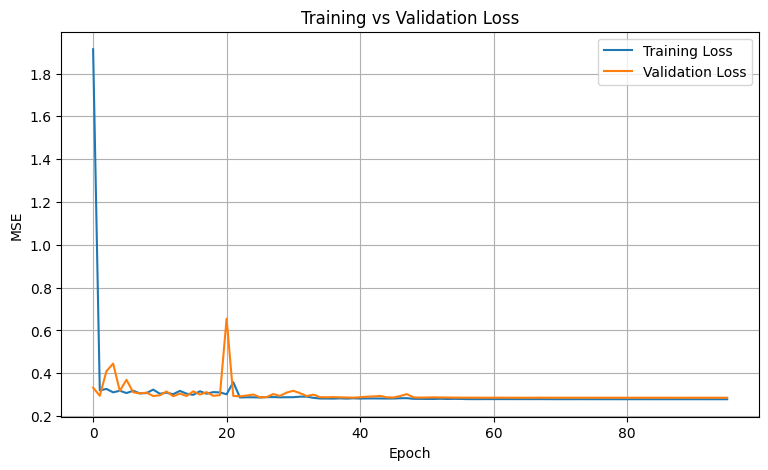

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid()
plt.show()

In [6]:
import numpy as np
import pandas as pd
import tensorflow as tf

# --- 1. Load the data and split exactly as in training ---
df = pd.read_csv("data_group5.csv")
df.drop(columns=["sr_no"], inplace=True)
x, y = df.iloc[:, 0:3], df.iloc[:, 3]

x_train, y_train = x[:21000],      y[:21000]
x_val,   y_val   = x[21000:25500], y[21000:25500]
x_test,  y_test  = x[25500:],      y[25500:]

# --- 2. Add the 4th feature g = y*z/(1+z^2) on RAW values, then scale ---
def add_feature(d):
    d = d.copy()
    d['g'] = d['y'] * d['z'] / (1 + d['z'] ** 2)
    return d

x_train_f = add_feature(x_train)
x_val_f   = add_feature(x_val)
x_test_f  = add_feature(x_test)

# Scale with TRAINING statistics (identical to training)
mean, std = x_train_f.mean(), x_train_f.std()
xte = ((x_test_f - mean) / std).values.astype("float32")
xva = ((x_val_f  - mean) / std).values.astype("float32")
yte = y_test.values.astype("float32")
yva = y_val.values.astype("float32")

# --- 3. Load the saved model (no training) ---
model = tf.keras.models.load_model("model_group5.keras", compile=False)
model.summary()
assert model.input_shape == (None, 4), f"Model expects {model.input_shape}, got 4 features"

# --- 4. Predict and evaluate on the test set ---
p = model.predict(xte, verbose=0).flatten()
e = np.abs(yte - p)

ss_res = np.sum((yte - p) ** 2)
ss_tot = np.sum((yte - yte.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print(f"\nTest MSE : {np.mean((yte - p)**2):.4f}")
print(f"Test RMSE: {np.sqrt(np.mean((yte - p)**2)):.4f}")
print(f"Test MAE : {e.mean():.4f}")
print(f"Test R²  : {r2:.4f}")
print(f"Max error: {e.max():.4f}")

# --- 5. Error-order check (thresholds from the validation set) ---
M = np.abs(yva).max()
n = int(np.floor(np.log10(M)))
good_thr, ok_thr = 10.0**(n - 1), 10.0**n
print(f"\nM={M:.5f}, n={n}, good if e < {good_thr}, acceptable if e < {ok_thr}")
print("Total test samples        :", len(e))
print("good (e < good_thr)       :", (e < good_thr).sum())
print("order n-1 (1 <= e < 10)   :", ((e >= good_thr) & (e < ok_thr)).sum())
print("unacceptable (e >= 10)    :", (e >= ok_thr).sum())

# --- 6. Largest errors ---
for i in np.argsort(e)[-10:][::-1]:
    r = x_test.iloc[i]
    print(f"err={e[i]:.2f}  x={r.iloc[0]:.1f} y={r.iloc[1]:.1f} z={r.iloc[2]:.2f}  pred={p[i]:.2f} true={yte[i]:.2f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,289 (423.00 KB)

 Trainable params: 108,289 (423.00 KB)

 Non-trainable params: 0 (0.00 B)


Test MSE : 0.2770
Test RMSE: 0.5263
Test MAE : 0.4311
Test R²  : 0.9896
Max error: 1.3461

M=48.04125, n=1, good if e < 1.0, acceptable if e < 10.0
Total test samples        : 4500
good (e < good_thr)       : 4289
order n-1 (1 <= e < 10)   : 211
unacceptable (e >= 10)    : 0
err=1.35  x=25.5 y=91.1 z=-0.52  pred=-36.55 true=-37.89
err=1.34  x=-64.9 y=25.1 z=14.44  pred=2.33 true=3.67
err=1.31  x=-75.5 y=-87.9 z=1.92  pred=-35.62 true=-34.32
err=1.29  x=-70.4 y=-83.9 z=20.65  pred=-3.37 true=-4.65
err=1.28  x=-29.6 y=-50.2 z=26.77  pred=-1.24 true=0.03
err=1.28  x=-4.7 y=10.3 z=33.02  pred=0.96 true=2.24
err=1.27  x=87.1 y=-85.1 z=61.45  pred=-0.90 true=0.37
err=1.27  x=67.5 y=-60.6 z=-36.10  pred=2.27 true=3.54
err=1.27  x=11.2 y=-91.0 z=-52.01  pred=2.28 true=3.55
err=1.26  x=-10.7 y=57.5 z=45.26  pred=1.92 true=3.18


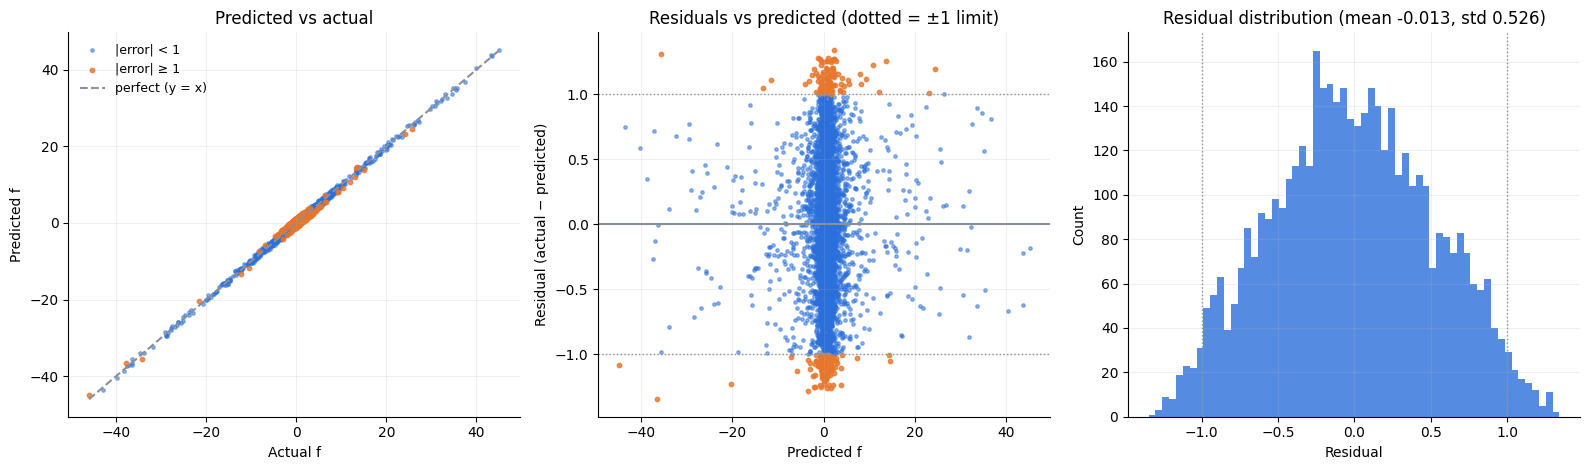

211 of 4500 test points have |error| ≥ 1


In [7]:
import numpy as np
import matplotlib.pyplot as plt

res = yte - p                      # residual = actual - predicted
good_thr = 1.0                     # from your validation-set M
bad = np.abs(res) >= good_thr      # errors of order n-1

BLUE, ORANGE, GREY = "#2a6fdb", "#e8762b", "#8a8f98"
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a in ax:
    a.grid(alpha=0.2); a.spines[["top", "right"]].set_visible(False)

# 1) Predicted vs actual
ax[0].scatter(yte[~bad], p[~bad], s=6, c=BLUE, alpha=0.5, label=f"|error| < {good_thr:g}")
ax[0].scatter(yte[bad],  p[bad],  s=10, c=ORANGE, alpha=0.8, label=f"|error| ≥ {good_thr:g}")
lim = [min(yte.min(), p.min()), max(yte.max(), p.max())]
ax[0].plot(lim, lim, c=GREY, lw=1.5, ls="--", label="perfect (y = x)")
ax[0].set(xlabel="Actual f", ylabel="Predicted f", title="Predicted vs actual")
ax[0].legend(frameon=False, fontsize=9)

# 2) Residuals vs predicted
ax[1].scatter(p[~bad], res[~bad], s=6, c=BLUE, alpha=0.5)
ax[1].scatter(p[bad],  res[bad],  s=10, c=ORANGE, alpha=0.8)
ax[1].axhline(0, c=GREY, lw=1.5)
for t in (-good_thr, good_thr):
    ax[1].axhline(t, c=GREY, lw=1, ls=":")
ax[1].set(xlabel="Predicted f", ylabel="Residual (actual − predicted)",
          title="Residuals vs predicted (dotted = ±1 limit)")

# 3) Residual histogram
ax[2].hist(res, bins=60, color=BLUE, alpha=0.8)
for t in (-good_thr, good_thr):
    ax[2].axvline(t, c=GREY, lw=1, ls=":")
ax[2].set(xlabel="Residual", ylabel="Count",
          title=f"Residual distribution (mean {res.mean():.3f}, std {res.std():.3f})")

plt.tight_layout()
plt.show()
print(f"{bad.sum()} of {len(res)} test points have |error| ≥ {good_thr:g}")